# CART RainNext24h: decision tree and rules

Workbook ID 30. Draws and explains the decision tree of **CART model v1**, the artifact selected on validation 2024 (ID 28) and evaluated once on test 2025 (ID 29). The model is not refitted or changed here.

**Data scope.** Model: `gold/ml_models/cart_rain_next24h_v1/model.joblib`; its SHA-256 is checked against `test_evaluation.json` below. Rule statistics (rows per leaf, observed Rain share) use the **train split (2016–2023)** the tree was fitted on. The worked examples use test 2025 predictions from ID 29, for explanation only; the error profile uses validation 2024.

**Units.** The pipeline does not scale numeric features, so every threshold is in the original unit (mm, %, hPa, °C). Open-Meteo rainfall has a 0.1 mm resolution: `≤ 0.05 mm` means *no rain*, and `> 0.35 mm` means *at least 0.4 mm*. `location` conditions come from one-hot columns. The probability threshold for predicting Rain is **0.40** (chosen on validation).

**Caveats.** Rules describe what the model learned from Open-Meteo reanalysis; they are not causal mechanisms or a verified real-time forecast. Splits are greedy, so a variable that does not appear can still be informative through correlated variables.

**Reproduce.** `make notebook-setup` once, then `make notebook-run NOTEBOOK=cart_tree_rules.ipynb` with MinIO holding the ID 23–29 artifacts. The computations live in `scripts/cart_rules.py` (tested in `tests/test_cart_rules.py`).

In [1]:
import io
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cart_rules as cr
from build_rain_features import features_keys
from evaluate_cart_test import evaluation_keys
from export_rain_labels import read_open_meteo_silver
from load_gold_observations import get_minio_client
from train_cart import _get, drop_missing, read_split

pd.set_option("display.max_colwidth", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# Validated reference palette (dataviz skill): light surface, recessive chrome
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SERIES_1 = "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "font.family": "sans-serif", "figure.dpi": 110, "axes.axisbelow": True,
})

## Load the evaluated model

In [2]:
client = get_minio_client()
model, report, sha = cr.load_artifacts(client)
evaluation = json.loads(_get(client, evaluation_keys()[0]))
assert sha == evaluation["model_sha256"], "this is not the model evaluated on test 2025"

features = [f["name"] for f in report["features"]]
cols = [*features, "location_code"]
units = cr.short_units(report)
threshold = report["probability_threshold"]
train, _ = drop_missing(read_split(client, "train"), features)
x_train, y_train = train[cols], train["rain_next24h"].to_numpy(bool)

tree = model.named_steps["tree"]
print(f"model SHA-256 {sha[:16]}… matches the test evaluation")
print(f"parameters {report['selected_params']}; depth {tree.get_depth()}, leaves {tree.get_n_leaves()}")
print(f"train rows used for rule statistics: {len(train):,}; probability threshold {threshold}")

model SHA-256 1f667b91365752a2… matches the test evaluation
parameters {'max_depth': 8, 'min_samples_leaf': 50, 'class_weight': 'balanced', 'ccp_alpha': 0.0001}; depth 8, leaves 88
train rows used for rule statistics: 560,640; probability threshold 0.4


## 1. The top of the tree

The full tree has 8 levels and 88 leaves, which is unreadable as one picture. The figure shows the **first 3 levels**; deeper subtrees are collapsed. Each box shows the split question, the number of train rows reaching the node, and the observed share of Rain among them. Box colour encodes that share (light = rarely rain, dark = mostly rain). The left branch (*yes*) holds the rows that satisfy the question.

,node,depth,branch,split,rows,observed_rain_share
0,0,0,None,rain_past_12h_mm ≤ 0.35 mm,560640,0.509
1,1,1,yes,dew_point_c ≤ 20.15 °C,288873,0.261
2,2,2,yes,rain_past_12h_mm ≤ 0.05 mm,152892,0.152
3,3,3,yes,dew_point_c ≤ 14.55 °C,127694,0.117
4,30,3,no,precipitation_mm ≤ 0.05 mm,25198,0.326
5,43,2,no,rain_past_24h_mm ≤ 0.25 mm,135981,0.383
6,44,3,yes,cloud_cover_percent ≤ 19.5 %,79927,0.303
7,77,3,no,precipitation_mm ≤ 0.05 mm,56054,0.497
8,100,1,no,precipitation_mm ≤ 0.05 mm,271767,0.773
9,101,2,yes,dew_point_c ≤ 21.95 °C,116952,0.624


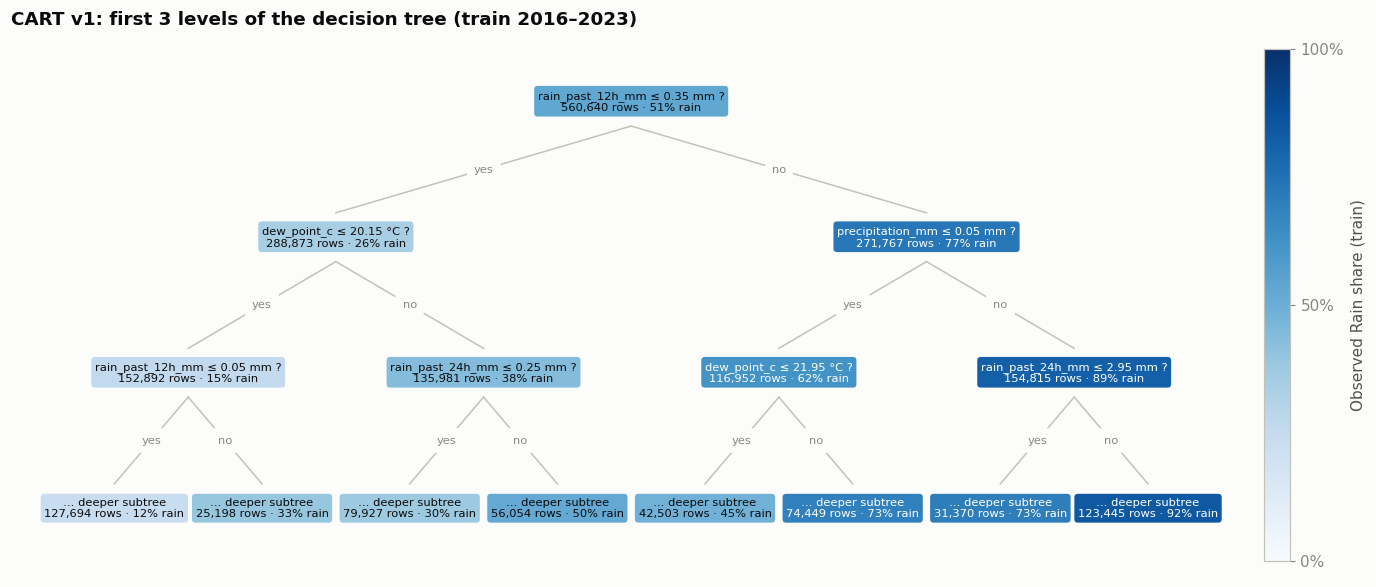

In [3]:
DEPTH = 3
nodes = cr.node_table(model, x_train, y_train, units, max_depth=DEPTH)
display(nodes[["node", "depth", "branch", "split", "rows", "observed_rain_share"]])

# Layout: leaves of the displayed tree get consecutive x positions; parents sit above their children
children = {n: list(g["node"]) for n, g in nodes.dropna(subset=["parent"]).groupby("parent")}
pos, next_x = {}, [0]
def place(n):
    kids = children.get(n, [])
    if not kids:
        pos[n] = next_x[0]; next_x[0] += 1
    else:
        for k in kids: place(k)
        pos[n] = np.mean([pos[k] for k in kids])
place(0)

info = nodes.set_index("node")
cmap = plt.get_cmap("Blues")
fig, ax = plt.subplots(figsize=(15, 6.4))
ax.set_axis_off(); ax.grid(False)
for n, r in info.iterrows():
    x, y = pos[n], -r["depth"]
    if not pd.isna(r["parent"]):
        px, py = pos[int(r["parent"])], -(r["depth"] - 1)
        ax.plot([px, x], [py - 0.18, y + 0.18], color="#c3c2b7", linewidth=1, zorder=1)
        ax.text((px + x) / 2, (py + y) / 2, r["branch"], fontsize=7.5, color=MUTED,
                ha="center", va="center", backgroundcolor=SURFACE, zorder=2)
    share = r["observed_rain_share"]
    if r["is_leaf"]:
        head = "leaf"
    elif r["depth"] == DEPTH:
        head = "… deeper subtree"
    else:
        head = r["split"].replace(" AND ", "\n") + " ?"
    text = f"{head}\n{r['rows']:,} rows · {share:.0%} rain"
    face = cmap(0.15 + 0.75 * share)
    ax.text(x, y, text, ha="center", va="center", fontsize=7.5, zorder=3,
            color="white" if share > 0.55 else INK,
            bbox=dict(boxstyle="round,pad=0.45", facecolor=face, edgecolor=SURFACE, linewidth=2))
ax.set_xlim(-0.7, next_x[0] - 0.3); ax.set_ylim(-DEPTH - 0.5, 0.5)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
cbar = fig.colorbar(sm, ax=ax, fraction=0.02, pad=0.01)
cbar.set_label("Observed Rain share (train)")
cbar.set_ticks([0, 0.5, 1], labels=["0%", "50%", "100%"])
ax.set_title("CART v1: first 3 levels of the decision tree (train 2016–2023)")
plt.show()

## 2. Classification rules

Each leaf is one rule: the conditions on its root-to-leaf path, merged into one interval per variable. *Rows* and *observed Rain share* come from the train split; *model probability* is the leaf output and decides the class with the 0.40 threshold. Rules are ordered by how many train rows they cover.

In [4]:
rules = cr.leaf_rules(model, x_train, y_train, threshold, units)
show = ["rows", "row_share", "observed_rain_share", "model_probability", "rule"]
print("Top 10 rules predicting Rain")
display(rules[rules["predicted_rain"]].head(10)[show])
print("Top 10 rules predicting No rain")
display(rules[~rules["predicted_rain"]].head(10)[show])

Top 10 rules predicting Rain


,rows,row_share,observed_rain_share,model_probability,rule
0,69273,0.124,0.969,0.968,rain_past_12h_mm > 0.35 mm AND precipitation_mm > 0.25 mm AND rain_past_24h_mm > 2.95 mm AND pressure_hpa ≤ 1015.35 hPa AND humidity_mean_6h_percent > 80.42 %
2,29153,0.052,0.853,0.848,rain_past_12h_mm > 0.35 mm AND precipitation_mm ≤ 0.05 mm AND dew_point_c > 23.25 °C AND rain_past_24h_mm > 2.75 mm AND cloud_cover_mean_6h_percent > 61.58 % AND rain_past_6h_mm > 0.05 mm
3,24030,0.043,0.919,0.917,rain_past_12h_mm > 0.35 mm AND 0.05 < precipitation_mm ≤ 0.25 mm AND rain_past_24h_mm > 2.95 mm AND pressure_hpa ≤ 1005.65 hPa
9,12188,0.022,0.867,0.863,rain_past_12h_mm > 0.35 mm AND 0.05 < precipitation_mm ≤ 0.25 mm AND rain_past_24h_mm > 2.95 mm AND 1005.65 < pressure_hpa ≤ 1015.35 hPa AND humidity_percent > 81.5 %
12,10753,0.019,0.583,0.575,rain_past_12h_mm > 0.35 mm AND precipitation_mm ≤ 0.05 mm AND dew_point_c ≤ 21.95 °C AND 1006.35 < pressure_hpa ≤ 1015.15 hPa AND humidity_percent > 76.5 % AND rain_past_6h_mm > 0.05 mm
15,9138,0.016,0.747,0.741,rain_past_12h_mm > 0.35 mm AND precipitation_mm ≤ 0.05 mm AND dew_point_c > 21.95 °C AND rain_past_24h_mm > 2.75 mm AND cloud_cover_mean_6h_percent > 61.58 % AND rain_past_6h_mm ≤ 0.05 mm
16,8601,0.015,0.796,0.790,rain_past_12h_mm > 0.35 mm AND 0.05 < precipitation_mm ≤ 0.25 mm AND 1.15 < rain_past_24h_mm ≤ 2.95 mm AND pressure_hpa ≤ 1016.55 hPa AND humidity_percent > 76.5 %
17,7733,0.014,0.870,0.866,rain_past_12h_mm > 0.35 mm AND precipitation_mm > 0.25 mm AND rain_past_24h_mm ≤ 2.95 mm AND pressure_hpa ≤ 1016.55 hPa AND humidity_percent > 76.5 %
19,7263,0.013,0.716,0.709,rain_past_12h_mm > 0.35 mm AND precipitation_mm ≤ 0.05 mm AND dew_point_c > 21.95 °C AND 1.35 < rain_past_24h_mm ≤ 2.75 mm AND cloud_cover_percent > 23.5 % AND pressure_change_24h_hpa > -1.75 hPa
20,7168,0.013,0.638,0.629,rain_past_12h_mm > 0.35 mm AND precipitation_mm ≤ 0.05 mm AND dew_point_c > 21.95 °C AND rain_past_24h_mm > 2.75 mm AND cloud_cover_mean_6h_percent ≤ 61.58 % AND location ≠ LCA


Top 10 rules predicting No rain


,rows,row_share,observed_rain_share,model_probability,rule
1,39695,0.071,0.032,0.031,rain_past_12h_mm ≤ 0.05 mm AND dew_point_c ≤ 14.55 °C AND cloud_cover_percent ≤ 96.5 % AND location ≠ LCA
4,22520,0.040,0.240,0.234,rain_past_12h_mm ≤ 0.35 mm AND 20.15 < dew_point_c ≤ 25.35 °C AND rain_past_24h_mm ≤ 0.05 mm AND cloud_cover_percent > 19.5 % AND pressure_change_24h_hpa ≤ 1.85 hPa AND location ≠ LCA
5,15987,0.029,0.122,0.118,rain_past_12h_mm ≤ 0.05 mm AND 14.55 < dew_point_c ≤ 20.15 °C AND 22.5 < cloud_cover_percent ≤ 97.5 % AND pressure_hpa > 1006.25 hPa AND month_local ≥ 3
6,15185,0.027,0.231,0.225,rain_past_12h_mm ≤ 0.05 mm AND 14.55 < dew_point_c ≤ 20.15 °C AND cloud_cover_percent > 97.5 % AND pressure_hpa > 1006.45 hPa AND month_local ≥ 2
7,13851,0.025,0.382,0.373,rain_past_12h_mm ≤ 0.05 mm AND 20.15 < dew_point_c ≤ 25.95 °C AND 0.25 < rain_past_24h_mm ≤ 1.95 mm AND precipitation_mm ≤ 0.05 mm AND cloud_cover_percent > 10.5 %
8,13756,0.025,0.053,0.051,rain_past_12h_mm ≤ 0.05 mm AND 14.55 < dew_point_c ≤ 20.15 °C AND cloud_cover_percent ≤ 22.5 % AND pressure_hpa > 1008.75 hPa
10,12068,0.022,0.063,0.061,rain_past_12h_mm ≤ 0.05 mm AND dew_point_c ≤ 14.55 °C AND cloud_cover_percent > 96.5 % AND pressure_hpa > 1018.05 hPa
11,11550,0.021,0.348,0.340,rain_past_12h_mm ≤ 0.35 mm AND 20.15 < dew_point_c ≤ 25.35 °C AND 0.05 < rain_past_24h_mm ≤ 0.25 mm AND cloud_cover_percent > 19.5 % AND pressure_change_24h_hpa ≤ 1.85 hPa
13,9840,0.018,0.175,0.170,rain_past_12h_mm ≤ 0.05 mm AND dew_point_c ≤ 14.55 °C AND cloud_cover_percent > 96.5 % AND pressure_hpa ≤ 1018.05 hPa
14,9470,0.017,0.311,0.303,rain_past_12h_mm ≤ 0.35 mm AND dew_point_c > 25.35 °C AND rain_past_24h_mm ≤ 0.25 mm AND cloud_cover_percent > 19.5 % AND cloud_cover_mean_6h_percent ≤ 96.42 % AND month_local ≤ 8 AND pressure_change_24h_hpa ≤ 1.05 hPa


In [5]:
coverage = rules["row_share"].cumsum()
summary_rules = {
    "leaves": len(rules),
    "leaves_predicting_rain": int(rules["predicted_rain"].sum()),
    "train_share_covered_by_top_5_rules": round(float(coverage.iloc[4]), 3),
    "train_share_covered_by_top_10_rules": round(float(coverage.iloc[9]), 3),
    "conditions_per_rule_min_max": (int(rules["n_conditions"].min()), int(rules["n_conditions"].max())),
    "max_abs_gap_model_probability_vs_observed_share": round(
        float((rules["model_probability"] - rules["observed_rain_share"]).abs().max()), 3),
}
summary_rules

{'leaves': 88,
 'leaves_predicting_rain': 52,
 'train_share_covered_by_top_5_rules': 0.329,
 'train_share_covered_by_top_10_rules': 0.456,
 'conditions_per_rule_min_max': (4, 7),
 'max_abs_gap_model_probability_vs_observed_share': 0.009}

## 3. Which variables the tree relies on

Impurity-based importance from the fitted tree (sums to 1). It describes this model only; it is not causal, and correlated variables share credit.

,importance
feature,
rain_past_12h_mm,0.647
dew_point_c,0.115
precipitation_mm,0.095
rain_past_24h_mm,0.057
pressure_hpa,0.027
cloud_cover_percent,0.019
humidity_percent,0.010
pressure_change_24h_hpa,0.010
cloud_cover_mean_6h_percent,0.006


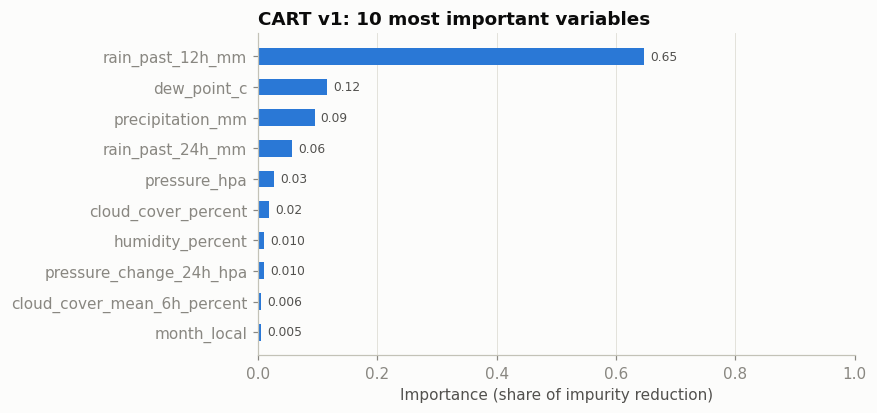

In [6]:
imp = pd.DataFrame(report["feature_importances"]).set_index("feature")["importance"]
display(imp.to_frame())
top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(top.index, top.values, color=SERIES_1, height=0.55)
for yy, v in enumerate(top.values):
    ax.text(v + 0.01, yy, f"{v:.2f}" if v >= 0.01 else f"{v:.3f}", va="center", fontsize=8, color=INK_2)
ax.set_xlim(0, 1); ax.set_xlabel("Importance (share of impurity reduction)")
ax.grid(axis="y", visible=False)
ax.set_title("CART v1: 10 most important variables")
plt.show()

## 4. Worked examples from test 2025

Four test predictions from ID 29, chosen by fixed rules rather than by hand:
- **Correct rain**: the true positive with the largest observed rain total.
- **False alarm**: the false positive with the highest predicted probability.
- **Missed rain, extreme**: the false negative with the largest observed rain total. It is chosen for its size, so it is *not* typical.
- **Missed rain, typical**: among misses with probability 0.30–0.40 and under 5 mm (the most common kind, see §5), the one whose rain total is closest to the median miss; ties go to the earliest origin.

Each table lists the questions the row answered from root to leaf, with its value at *t*. The extreme miss also gets its hourly context from Silver, because its features alone hide what happened.

In [7]:
split_keys, _ = features_keys()
test = pd.read_parquet(io.BytesIO(_get(client, split_keys["test"])))
preds = pd.read_parquet(io.BytesIO(_get(client, evaluation_keys()[1])))
test = test.merge(preds[["location_code", "origin_utc", "probability", "predicted_rain"]],
                  on=["location_code", "origin_utc"], validate="one_to_one")

cases = {
    "Correct rain (TP)": test[test["predicted_rain"] & test["rain_next24h"]].nlargest(1, "rain_next24h_mm"),
    "False alarm (FP)": test[test["predicted_rain"] & ~test["rain_next24h"]].nlargest(1, "probability"),
    "Missed rain, extreme (FN)": test[~test["predicted_rain"] & test["rain_next24h"]].nlargest(1, "rain_next24h_mm"),
}
missed = test[~test["predicted_rain"] & test["rain_next24h"]]
typical = missed[missed["probability"].between(0.30, threshold, inclusive="left") & (missed["rain_next24h_mm"] < 5)]
typical = typical.assign(gap=(typical["rain_next24h_mm"] - missed["rain_next24h_mm"].median()).abs())
cases["Missed rain, typical (FN)"] = typical.sort_values(["gap", "origin_utc"]).head(1)
for name, row in cases.items():
    r = row.iloc[0]
    local = (r["origin_utc"] + pd.Timedelta(hours=7)).strftime("%Y-%m-%d %H:%M")
    print(f"{name}: {r['location_code']} at {local} Vietnam time; "
          f"probability {r['probability']:.2f}; next-24 h rain {r['rain_next24h_mm']:.1f} mm")
    display(cr.decision_path(model, row[cols], units))

Correct rain (TP): HAN at 2025-10-06 11:00 Vietnam time; probability 0.97; next-24 h rain 144.6 mm


,condition,value_at_t
0,rain_past_12h_mm > 0.35 mm,23.900
1,precipitation_mm > 0.05 mm,2.000
2,rain_past_24h_mm > 2.95 mm,27.000
3,pressure_hpa ≤ 1015.35 hPa,"1,002.700"
4,precipitation_mm > 0.25 mm,2.000
5,humidity_mean_6h_percent > 80.42 %,90.500


False alarm (FP): HAN at 2025-02-16 04:00 Vietnam time; probability 0.97; next-24 h rain 0.7 mm


,condition,value_at_t
0,rain_past_12h_mm > 0.35 mm,6.500
1,precipitation_mm > 0.05 mm,0.500
2,rain_past_24h_mm > 2.95 mm,6.600
3,pressure_hpa ≤ 1015.35 hPa,"1,012.000"
4,precipitation_mm > 0.25 mm,0.500
5,humidity_mean_6h_percent > 80.42 %,95.500


Missed rain, extreme (FN): NBI at 2025-09-26 11:00 Vietnam time; probability 0.39; next-24 h rain 57.9 mm


,condition,value_at_t
0,rain_past_12h_mm ≤ 0.35 mm,0.100
1,dew_point_c > 20.15 °C,24.400
2,rain_past_24h_mm ≤ 0.25 mm,0.200
3,cloud_cover_percent > 19.5 %,100.000
4,dew_point_c ≤ 25.35 °C,24.400
5,pressure_change_24h_hpa > 1.85 hPa,6.900
6,month_local ≥ 4,9.000
7,month_local ≤ 10,9.000


Missed rain, typical (FN): LCA at 2025-03-28 16:00 Vietnam time; probability 0.36; next-24 h rain 3.0 mm


,condition,value_at_t
0,rain_past_12h_mm ≤ 0.35 mm,0.000
1,dew_point_c > 20.15 °C,22.100
2,rain_past_24h_mm ≤ 0.25 mm,0.000
3,cloud_cover_percent ≤ 19.5 %,6.000
4,pressure_change_24h_hpa > 1.45 hPa,5.600


### Hourly context of the extreme miss

Silver Open-Meteo hours around the origin, in Vietnam time. Rain began in the first hour after *t* (0.1 mm, then heavier from *t*+2h); 0.1 mm of drizzle had also fallen one hour before *t*. At *t* the sky was fully overcast, the wind blew from the north, humidity was 76% after about 90% in the morning, and pressure was 6.9 hPa higher than a day earlier, a pattern consistent with a cold-air surge. The wind turned north-east only after the rain had started. The model has no wind-direction feature, and its leaf for this case holds about 39% Rain in train, so it returned a probability just under 0.40.

In [8]:
case = cases["Missed rain, extreme (FN)"].iloc[0]
ctx_cols = ["precipitation_mm", "pressure_hpa", "humidity_percent", "cloud_cover_percent",
            "wind_speed_ms", "wind_direction_deg"]
ctx = read_open_meteo_silver(client, 2025, 2025, columns=["location_code", "timestamp_utc", *ctx_cols])
ctx = ctx[ctx["location_code"] == case["location_code"]].set_index("timestamp_utc")
ctx = ctx.loc[case["origin_utc"] - pd.Timedelta(hours=6):case["origin_utc"] + pd.Timedelta(hours=12), ctx_cols]
ctx.index = (ctx.index + pd.Timedelta(hours=7)).strftime("%m-%d %H:%M") + " (t" + [
    f"{int((ts - case['origin_utc']) / pd.Timedelta(hours=1)):+d}h" for ts in ctx.index.tz_convert("UTC")] + ")"
leaf = model.named_steps["tree"].apply(model.named_steps["pre"].transform(cases["Missed rain, extreme (FN)"][cols]))[0]
print("leaf", leaf, rules.set_index("leaf").loc[leaf, ["rows", "observed_rain_share", "model_probability"]].astype(float).round(3).to_dict())
display(ctx)

leaf 64 {'rows': 2143.0, 'observed_rain_share': 0.394, 'model_probability': 0.385}


,precipitation_mm,pressure_hpa,humidity_percent,cloud_cover_percent,wind_speed_ms,wind_direction_deg
timestamp_utc,,,,,,
09-26 05:00 (t-6h),0.000,"1,006.500",89.000,100.000,2.580,345.000
09-26 06:00 (t-5h),0.000,"1,007.400",90.000,100.000,2.470,342.000
09-26 07:00 (t-4h),0.000,"1,008.100",89.000,100.000,2.170,352.000
09-26 08:00 (t-3h),0.000,"1,009.400",89.000,100.000,3.200,346.000
09-26 09:00 (t-2h),0.000,"1,010.100",84.000,99.000,3.660,346.000
09-26 10:00 (t-1h),0.100,"1,009.900",81.000,70.000,3.810,349.000
09-26 11:00 (t+0h),0.000,"1,009.800",76.000,100.000,3.250,1.000
09-26 12:00 (t+1h),0.100,"1,009.000",73.000,100.000,3.110,6.000
09-26 13:00 (t+2h),0.900,"1,008.100",76.000,100.000,4.400,36.000


## 5. Where the model misses rain (validation 2024)

One example cannot show a pattern, so the misses are profiled on **validation 2024** (the period used for selection, not test). The profile only describes errors; nothing here changes the model or the threshold.

*Onset* is the first hour in the target window with any rain. *Dry past 24 h* means at most 0.05 mm (no rain at 0.1 mm resolution) in the 24 hours ending at *t*.

,validation_2024
rain_cases,"34,636.000"
missed,"6,160.000"
missed_share_of_rain,0.178
missed_with_probability_0_30_to_threshold,0.553
missed_under_5_mm,0.642
missed_median_mm,2.900
missed_dry_past_24h,0.361
recall_after_wet_24h,0.877
recall_after_dry_24h,0.170
recall_after_dry_24h_dry_season,0.026


,onset,cases,recall
0,1-3 h,22679,0.909
1,4-6 h,4346,0.709
2,7-12 h,4782,0.656
3,13-18 h,2253,0.613
4,19-24 h,576,0.450


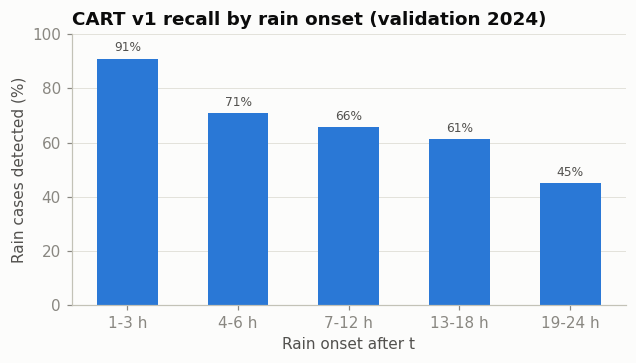

In [9]:
val, _ = drop_missing(read_split(client, "validation"), features)
val["probability"] = model.predict_proba(val[cols])[:, 1]
hourly = read_open_meteo_silver(client, 2024, 2025, columns=["location_code", "timestamp_utc", "precipitation_mm"])
val = val.merge(cr.hours_to_first_rain(hourly), on=["location_code", "origin_utc"], how="left", validate="one_to_one")
profile = cr.missed_rain_profile(val, threshold)
display(pd.Series({k: v for k, v in profile.items() if k != "recall_by_onset"}).to_frame("validation_2024"))
by_onset = profile["recall_by_onset"]
display(by_onset)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
bars = ax.bar(by_onset["onset"].astype(str), by_onset["recall"] * 100, color=SERIES_1, width=0.55)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in by_onset["recall"] * 100], color=INK_2, padding=3, fontsize=8)
ax.set_ylim(0, 100); ax.set_ylabel("Rain cases detected (%)"); ax.set_xlabel("Rain onset after t")
ax.grid(axis="x", visible=False)
ax.set_title("CART v1 recall by rain onset (validation 2024)")
plt.show()

## 6. Key numbers for the report

Computed, not typed, so they always match the cells above.

In [10]:
root = info.loc[0]
summary = {
    "model_sha256_prefix": sha[:16],
    "depth_and_leaves": (tree.get_depth(), tree.get_n_leaves()),
    "root_split": root["split"],
    "root_yes_rows_and_rain_share": tuple(
        info[(info["parent"] == 0) & (info["branch"] == "yes")][["rows", "observed_rain_share"]].round(3).iloc[0]),
    "root_no_rows_and_rain_share": tuple(
        info[(info["parent"] == 0) & (info["branch"] == "no")][["rows", "observed_rain_share"]].round(3).iloc[0]),
    "largest_rain_rule": rules[rules["predicted_rain"]].iloc[0][["rows", "observed_rain_share", "rule"]].tolist(),
    "largest_no_rain_rule": rules[~rules["predicted_rain"]].iloc[0][["rows", "observed_rain_share", "rule"]].tolist(),
    "top3_importances": imp.head(3).round(3).to_dict(),
    "test_f1_from_id29": round(evaluation["test_metrics_at_threshold"]["f1"], 3),
    "validation_missed_share_of_rain": round(profile["missed_share_of_rain"], 3),
    "validation_missed_near_threshold_0_30": round(profile["missed_with_probability_0_30_to_threshold"], 3),
    "validation_missed_under_5_mm": round(profile["missed_under_5_mm"], 3),
    "validation_missed_dry_past_24h": round(profile["missed_dry_past_24h"], 3),
    "validation_recall_after_wet_vs_dry_24h": (round(profile["recall_after_wet_24h"], 3), round(profile["recall_after_dry_24h"], 3)),
    "validation_recall_after_dry_24h_dry_vs_wet_season": (
        round(profile["recall_after_dry_24h_dry_season"], 3), round(profile["recall_after_dry_24h_wet_season"], 3)),
}
summary

{'model_sha256_prefix': '1f667b91365752a2',
 'depth_and_leaves': (8, 88),
 'root_split': 'rain_past_12h_mm ≤ 0.35 mm',
 'root_yes_rows_and_rain_share': (288873.0, 0.261),
 'root_no_rows_and_rain_share': (271767.0, 0.773),
 'largest_rain_rule': [69273,
  0.969295396474817,
  'rain_past_12h_mm > 0.35 mm AND precipitation_mm > 0.25 mm AND rain_past_24h_mm > 2.95 mm AND pressure_hpa ≤ 1015.35 hPa AND humidity_mean_6h_percent > 80.42 %'],
 'largest_no_rain_rule': [39695,
  0.03169164882226981,
  'rain_past_12h_mm ≤ 0.05 mm AND dew_point_c ≤ 14.55 °C AND cloud_cover_percent ≤ 96.5 % AND location ≠ LCA'],
 'top3_importances': {'rain_past_12h_mm': 0.647,
  'dew_point_c': 0.115,
  'precipitation_mm': 0.095},
 'test_f1_from_id29': 0.775,
 'validation_missed_share_of_rain': 0.178,
 'validation_missed_near_threshold_0_30': 0.553,
 'validation_missed_under_5_mm': 0.642,
 'validation_missed_dry_past_24h': 0.361,
 'validation_recall_after_wet_vs_dry_24h': (0.877, 0.17),
 'validation_recall_after_dry_

## Interpretation (model v1)

The figures below are those printed in §1, §2, and §5 for the frozen v1 artifact.

- **Recent rain comes first.** The root asks whether at most 0.35 mm fell in the past 12 hours (with 0.1 mm resolution: 0.3 mm or less). Without recent rain (*yes*, 288,873 train rows) 26% of origins are followed by Rain; with recent rain (*no*, 271,767 rows) 77% are. This one question carries about two thirds of the importance and explains why the persistence baseline is already strong.
- **Moisture decides the dry branch.** Without recent rain the tree asks about dew point. The largest No-rain rule (39,695 rows, 3% Rain) is: no rain in 12 h, dew point ≤ 14.55 °C, sky not fully overcast, and not Lào Cai.
- **Ongoing rain decides the wet branch.** With recent rain, still raining at *t* gives 89% Rain, and 92% when more than 2.95 mm fell over 24 h. The largest Rain rule (69,273 rows, 97% Rain) adds surface pressure ≤ 1015.35 hPa and a 6-hour mean humidity above 80.4%.
- **Pressure mixes weather and elevation.** `pressure_hpa` is surface pressure, so it is lower at higher research points (train mean about 1001 hPa at Lào Cai versus 1007–1010 hPa elsewhere). A pressure threshold therefore partly encodes location, not only weather systems.
- **Location and season enter late.** The first split on Lào Cai is at depth 5 and the first on month at depth 6, consistent with the EDA (Lào Cai is wetter all year; dry-season months rain less).
- **What the misses look like (validation 2024, §5).** Most misses are *light rain* and *near the threshold*: about two thirds are under 5 mm and over half had a probability of 0.30–0.40. Recall also falls as rain starts later in the window. Rain after a completely dry day is a smaller but very weak group: about a third of misses, detected only rarely, and almost never in the dry season.
- **The extreme miss is not "rain without warning".** At Ninh Bình rain began one hour after *t*, after light drizzle, under a fully overcast sky, a northerly wind, and pressure that had risen 6.9 hPa in a day. The model lacks a wind-direction feature, and the train leaf for this situation is itself uncertain (about 39% Rain), so it returned 0.39. Wind direction was never assessed in the EDA (ID 21); it was left out of features v1 without evidence. It is the first candidate for a feature v2, to be selected on validation only.
- **Limits.** §1 shows 3 of 8 levels; the tables list the most-populated leaves, and all 88 rules are in the appendix. The §4 examples are illustrations; §5 is the evidence. Rules describe correlations learned from reanalysis data. They are not physical laws, and operational use would need features that are available at forecast time.

## Appendix: all rules

In [11]:
display(rules[["leaf", "rows", "observed_rain_share", "model_probability", "predicted_rain", "rule"]])

,leaf,rows,observed_rain_share,model_probability,predicted_rain,rule
0,167,69273,0.969,0.968,True,rain_past_12h_mm > 0.35 mm AND precipitation_mm > 0.25 mm AND rain_past_24h_mm > 2.95 mm AND pressure_hpa ≤ 1015.35 hPa AND humidity_mean_6h_percent > 80.42 %
1,6,39695,0.032,0.031,False,rain_past_12h_mm ≤ 0.05 mm AND dew_point_c ≤ 14.55 °C AND cloud_cover_percent ≤ 96.5 % AND location ≠ LCA
2,143,29153,0.853,0.848,True,rain_past_12h_mm > 0.35 mm AND precipitation_mm ≤ 0.05 mm AND dew_point_c > 23.25 °C AND rain_past_24h_mm > 2.75 mm AND cloud_cover_mean_6h_percent > 61.58 % AND rain_past_6h_mm > 0.05 mm
3,161,24030,0.919,0.917,True,rain_past_12h_mm > 0.35 mm AND 0.05 < precipitation_mm ≤ 0.25 mm AND rain_past_24h_mm > 2.95 mm AND pressure_hpa ≤ 1005.65 hPa
4,58,22520,0.240,0.234,False,rain_past_12h_mm ≤ 0.35 mm AND 20.15 < dew_point_c ≤ 25.35 °C AND rain_past_24h_mm ≤ 0.05 mm AND cloud_cover_percent > 19.5 % AND pressure_change_24h_hpa ≤ 1.85 hPa AND location ≠ LCA
...,...,...,...,...,...,...
83,62,490,0.733,0.726,True,rain_past_12h_mm ≤ 0.35 mm AND 20.15 < dew_point_c ≤ 25.35 °C AND rain_past_24h_mm ≤ 0.25 mm AND cloud_cover_percent > 19.5 % AND pressure_change_24h_hpa > 1.85 hPa AND month_local ≤ 3
84,24,435,0.699,0.691,True,rain_past_12h_mm ≤ 0.05 mm AND 14.55 < dew_point_c ≤ 20.15 °C AND cloud_cover_percent > 97.5 % AND pressure_hpa ≤ 1006.45 hPa AND wind_speed_ms > 2.52 m/s
85,76,415,0.884,0.881,True,rain_past_12h_mm ≤ 0.35 mm AND dew_point_c > 25.35 °C AND rain_past_24h_mm ≤ 0.25 mm AND cloud_cover_percent > 19.5 % AND cloud_cover_mean_6h_percent > 96.42 % AND pressure_change_24h_hpa > 2.05 hPa
86,65,368,0.736,0.729,True,rain_past_12h_mm ≤ 0.35 mm AND 20.15 < dew_point_c ≤ 25.35 °C AND rain_past_24h_mm ≤ 0.25 mm AND cloud_cover_percent > 19.5 % AND pressure_change_24h_hpa > 1.85 hPa AND month_local ≥ 11
